# Binary Option pricing without cunterpary default risk

This notebook sets up the framework for the first part of the main method in this project. It aims to establish a verifiable baseline of the two neural methods. The problem will be used to varify know theory such and tune hyperparameters of the nueral model. This is done to later extend the problem to a non-linear (semi-linear) case where CVA is added (represented by the $f$ function in the canonical representation of semi-linear PDEs) to account for counterparty default. 

The purpose of this part is to establish *optimal* version of the two deep solvers in order to compare them in a semi-linear setting.

Dictionary of abbrieviations and expressions:
- **FC** - Fully Connected
- **MC** - Monte Carlo
- **DBSDE** - Deep Backward Stochastic Differential Equation (the neural solver)
- **Merged DBSDE** - varianrt of DBSDE with a shared network over all timeslots rather than separate discrete networsk for aech time increment
- **FC** - Fully Connected
- **CVA** - Credit Value Adjustment

**Problem:** price a binary basket call option using Monte Carlo (MC), FC DBSDE, FC DBSDE with extended inputs (e.g. $g(x)$, $Y_t$),  FC DBSDE with ELU activation,  Merged DSBDE, Merged BSDE with shortcuts (RNN structure).

Consider the multidimensional Black--Scholes PDE
\begin{equation}
     \partial_t u + \tfrac{1}{2}\operatorname{Tr}\!\big(\sigma\sigma^{\top}\nabla^2 u\big) + \mu\cdot\nabla u - ru = 0
\end{equation}
with the asset-or-nothing binary basket call terminal condition
\begin{equation}
    u(T,S) = g(S) = B(S)\,\mathbf{1}_{\{B(S) > K\}},
    \qquad B(S) = \sum_{i=1}^{d} w_i S^i,
\end{equation}


\begin{equation}
    B(S)\,\mathbf{1}_{\{B(S) > K\}} = \big(B(S) - K\big)^{+} + K\,\mathbf{1} _{\{B(S) > K\}}
\end{equation}

where $w_i \ge 0$ are the basket weights and $\sum_{i=1}^{d} w_i = 1$ (e.g.\ $w_i = 1/d$).
The underlying SDE is
\begin{equation}
    dS_t = \operatorname{diag}(r-q)\,S_t\,dt + \operatorname{diag}(S_t)\operatorname{diag}(\sigma)\,dW_t.
\end{equation}
In this implementation we consider $d = 100$, $S_0 = \xi$, $T=1$, $t = 0$, $q = 0$, and $\Delta t = T/N$ for the Deep BSDE solver. The reference MC estimate is
\begin{equation}
    u(0,\xi) \approx \frac{e^{-rT}}{M}\sum_{m=1}^{M} B\big(S_T^{(m)}\big)\,\mathbf{1}_{\{B(S_T^{(m)}) > K\}}.
\end{equation}

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import torch

First, sampling functions and payoff functions ca be defined

In [19]:
def sample_paths(xi, bs, d, N, dt, r=0.05, q=0.0, sigma=0.2):
    dW = np.sqrt(dt) * np.random.randn(bs, N, d)
    log_incr = (r - q - 0.5 * sigma**2) * dt + sigma * dW
    X = np.empty((bs, N + 1, d))
    X[:, 0] = xi
    X[:, 1:] = xi * np.exp(np.cumsum(log_incr, axis=1))
    return torch.tensor(X, dtype=torch.float32), torch.tensor(dW, dtype=torch.float32)


r = 0.05
def fun(Y):
    return -r*Y

def g_aon(x, K):
    # Asset-or-nothing payoff on equally weighted basket
    B = x.mean(-1)
    return B * (B > K).to(x.dtype)


def g_con(x, K, Q):
    # Cash-or-nothing payoff on equally weighted basket
    B = x.mean(-1)
    return Q * (B > K).to(x.dtype)

Then the MC solver can be written and tested, this will be used as the baseline when comparing deep solvers.

In [20]:
def mc_price(xi, n_paths, batch_size, d, N, dt, T, r, q, sigma, po_fun):
    payoffs = []
    for _ in range(n_paths // batch_size):
        X, _ = sample_paths(xi, batch_size, d=d, N=N, dt=dt, r=r, q=q, sigma = sigma)
        payoffs.append(po_fun(X[:, -1]))
    payoffs = torch.cat(payoffs).double()
    disc = np.exp(-r * T)
    price = disc * payoffs.mean().item()
    std_err = disc * payoffs.std().item() / np.sqrt(len(payoffs))
    return price, std_err

Verifying the MC solver and check convergence on a basket with $\xi = \operatorname{diag}(100)$

MC estimation: u = 82.14842041430677, se = 1.3073864047002897 with M = 1000
MC estimation: u = 79.38198847063416, se = 0.43093727909200846 with M = 10000
MC estimation: u = 79.29806983366991, se = 0.13615400332464234 with M = 100000
MC estimation: u = 79.18653415246851, se = 0.04311527257635272 with M = 1000000
MC estimation: u = 79.21456324714015, se = 0.030475032796080177 with M = 2000000
MC estimation: u = 79.26205117489377, se = 0.013618132636432877 with M = 10000000
MC estimation: u = 79.25229615738249, se = 0.004307077083245579 with M = 100000000


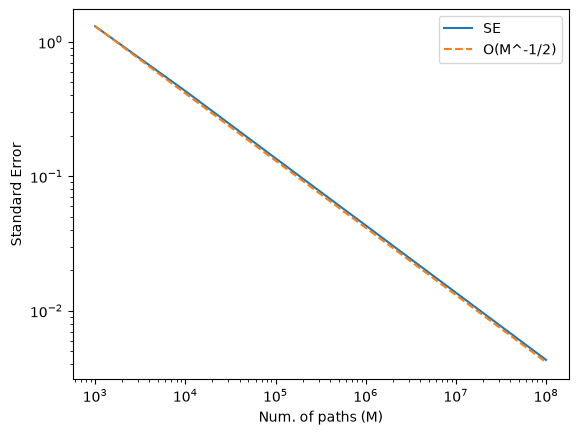

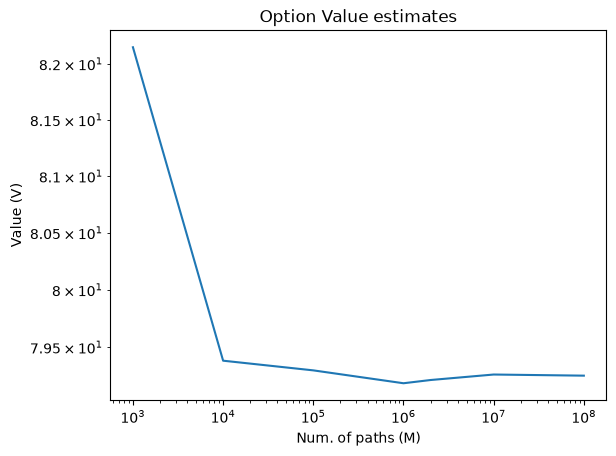

In [ ]:
d = 10
S0 = 100*np.ones(d)
T = 1
K = 100
N = 1
r = 0.05
q = 0.0
sigma = 0.2
dt = T / N

paths = [1000, 10_000, 100_000, 1_000_000, 10_000_000, 100_000_000]

est = []
err = []

for path in paths:
    mc, se = mc_price(S0, 
                      n_paths=path, 
                      batch_size=1000, 
                      d=d, 
                      N=N, 
                      dt=dt, 
                      T=T, 
                      r=r,
                      q=q,
                      sigma=sigma,
                      po_fun=lambda x: g_aon(x, K))
    err.append(se)
    est.append(mc)
    print(f"MC estimation: u = {mc}, se = {se} with M = {path}")

plt.loglog(paths, err, label = "SE")
plt.loglog(paths, err[0]*np.sqrt(paths[0]/np.array(paths)), '--', label='O(M^-1/2)')
plt.legend()
plt.xlabel('Num. of paths (M)')
plt.ylabel('Standard Error')
plt.show()

plt.loglog(paths, est)
plt.title('Option Value estimates')
plt.xlabel('Num. of paths (M)')
plt.ylabel('Value (V)')
plt.show()


Once MC baseline is established, expperimentation with DBSDE can begin